# Learned predictors served live from a portable document: the same prediction in Python and in the browser

**Question:** Can a learned model be served from a portable document with exactly the engine's predictions?

**Level 4: Beyond the state of the art** · Needs: 05-learned-arms/01-fitting-a-learned-arm-on-nine-sites, 06-design-response/02-a-burden-and-spacing-surface · Reading time: about 35 minutes

## Objectives

The web application recomputes every model, the learned ones included, on a design the reader changes, with no Python server behind it. That is possible because each learned predictor is exported once to a portable JSON document that a browser can evaluate (claim BS-5 of the design document). The claim is only worth something if the document gives the same prediction as the engine. This notebook exports predictors itself, reads the documents with the engine's reference reader, and measures the difference.

By the end you will have:

- fitted gradient boosting without Enusa, exported it with `export_arm` and looked inside the document;
- compared the portable prediction with the engine's on all 97 blasts, the 12 Enusa blasts the model never saw among them;
- exported the other four learned predictors and measured size and difference for each, and followed a design lever through the document;
- tampered with the committed document of the Enusa scope, seen what its content address does, and checked that a fresh export equals the committed one.

## Setup

Install the packages with the exact pins of `notebooks/requirements.txt`. The engine is `blastfrag`, published on PyPI; the other packages are its numerical base and the plotting library.

```bash
pip install blastfrag==0.4.0 numpy==2.5.4 matplotlib==3.11.2
```

The setup cell imports the packages, the product's variant tool `apply_variant` and its `digest` function (the content address of the committed models files), prints the versions, loads the corpus, and holds out Enusa: `fit_rows` are the 85 blasts of the other nine campaigns. It also defines `Table`.

In [1]:
# Imports, package versions and the corpus loader
from importlib.metadata import version
from pathlib import Path
import copy
import json
import sys

sys.path.insert(0, str(Path("../../../data-pipeline")))
from pipeline.cases.fragmenta_cases import Variant
from pipeline.model.blasts import apply_variant
from pipeline.stages.export import digest

import blastfrag as bf
import matplotlib.pyplot as plt
import numpy as np

for name in ("blastfrag", "numpy", "matplotlib"):
    print(f"{name}=={version(name)}")

DERIVED = Path("../../../data/derived")
train = bf.load_training_corpus()
print(len(train), "blasts from", len({b.site for b in train}), "campaigns")

class Table:
    """Rows under a header, shown as a Markdown table"""

    def __init__(self, header, rows):
        self.header = list(header)
        self.rows = [[str(cell) for cell in row] for row in rows]

    def _repr_markdown_(self):
        lines = ["| " + " | ".join(self.header) + " |", "|" + "---|" * len(self.header)]
        lines += ["| " + " | ".join(row) + " |" for row in self.rows]
        return "\n".join(lines)

    __repr__ = _repr_markdown_

held_out_site = "Enusa"
fit_rows = [blast for blast in train if blast.site != held_out_site]

blastfrag==0.4.0
numpy==2.5.4
matplotlib==3.11.2
97 blasts from 10 campaigns


## Data

| Source | Owner and URL | Licence class | File the notebook reads |
|---|---|---|---|
| The training rows | Hudaverdi, Kulatilake and Kuzu 2010, https://doi.org/10.1002/nag.957 | numeric facts reused with citation; the article never ships | the corpus inside the `blastfrag` wheel |
| The models file of the Enusa scope: the seven predictors fitted without any Enusa blast | this repository (MIT), written by the offline bake | the product's own licence | `data/derived/models/Enusa.json`, for the tamper and the final check |
| The index, which lists each models file with its digest | this repository (MIT), written by the offline bake | the product's own licence | `data/derived/manifests/index.json` |

The reader of the portable format is `bf.predict_portable`, in the engine. The browser has its own reader in TypeScript, which the product's test `frontend/test/parity.test.ts` holds to the committed documents.

## Method

A fitted learned predictor is not a pickle and not a model server. The engine writes it as a JSON document in a versioned schema (`blastfrag.portable/v1`) that holds exactly what a prediction needs: for the forest and the boosted model the trees as arrays of left and right children, split features and thresholds; the standardisation constants; for the support vector regressor the support vectors and the dual coefficients; for the network the layer weights; for the stacking ensemble a reference to the forest and the boosted model plus the meta-learner. Evaluating the document takes arithmetic only, so a reader written in TypeScript can reproduce it in a browser.

The claim BS-5 has three parts, and each is measured below: the document predicts what the engine predicts (steps 2 and 3), it follows a design the reader changes (step 4), and a stale or edited document cannot pass as the committed one (step 5 and the check). The difference between two readers of the same function is measured in metres, as the largest absolute difference over the 97 blasts.

## State of the art

- The learned predictors published for this corpus are reported through their scores and their parameters: the network widths (Kulatilake et al. 2012, https://doi.org/10.1007/s10706-012-9496-3), the support vector kernels and constants (Amoako et al. 2022, https://doi.org/10.3390/mining2020013; Sui et al. 2025, https://doi.org/10.3390/app15031254) and the boosting learning rate (Sui et al. 2025).
- The sources held for this work give no runnable form of any of them that a reader could apply to a new design. A reader who wants the prediction for a design has to retrain the model from the parameters, as notebook 03 of topic 05 does for the network.
- The conventional way to serve a learned model is a Python process behind an API, which the product's static deployment does not have.

So the state of the art offers a score and a recipe, not a function a browser can call. The claim beyond it is that the fitted function itself can be shipped, and the steps below test it.

## Beyond the state of the art

### Step 1: fit, export and look inside

The cell fits gradient boosting on the 85 blasts outside Enusa (the same fit as the product's Enusa scope), exports it with `export_arm`, serialises the document and prints what it holds: the schema, the kind of model, the number of trees, the size of the first tree and of the whole file, and the root node of the first tree.

In [2]:
# Fit gradient boosting without Enusa and export it to a portable document
model = bf.default_arms()["xgboost"]().fit(fit_rows)
document = bf.export_arm(model)
text = json.dumps(document)
trees = document["trees"]
print("schema:", document["schema"], "| kind:", document["kind"], "| engine:", document["engine_version"])
print("trees:", len(trees), "| nodes in the first tree:", len(trees[0]["t"]), "| JSON size:", len(text), "characters")
print("first tree, root:", {key: values[0] for key, values in trees[0].items()})
print("the root splits on:", document["features"][trees[0]["feature"][0]])

schema: blastfrag.portable/v1 | kind: xgboost | engine: 0.04.000
trees: 100 | nodes in the first tree: 29 | JSON size: 40032 characters
first tree, root: {'left': 1, 'right': 2, 'feature': 6, 't': 1.36735999584198}
the root splits on: E_GPa


**What the output shows.** The whole model is 100 trees, the first with 29 nodes, in 40,032 characters of JSON. Each node is four numbers: the children `left` and `right`, the `feature` index to split on and `t`, the threshold of a split or the value of a leaf. The root splits on the rock modulus, the feature the output names, at the threshold 1.367 (the inputs are standardised first, with constants the document carries). Nothing in it needs Python: walking the trees is a loop over arrays. **What it does not show:** that the walk gives the engine's answer, which is the next step.

### Step 2: the portable prediction against the engine's

`predict_portable` is the reference reader. The cell predicts all 97 blasts of the corpus twice, with the engine's own fitted model and with the document alone, and takes the difference. The 12 Enusa blasts are the ones the model was not trained on, so they test the document where a stale copy of the training data would not help.

In [3]:
# Evaluate the document with the reference reader on all 97 blasts and compare with the engine's own prediction
engine = np.array([p.x50_m for p in model.predict(train)])
portable = np.array([bf.predict_portable(document, blast)[0] for blast in train])
residual = portable - engine
print("blasts compared:", len(train), "| largest absolute difference:", f"{np.abs(residual).max():.1e}", "m")
print("blasts whose two predictions are bit-identical:", int((residual == 0).sum()))

blasts compared: 97 | largest absolute difference: 0.0e+00 m
blasts whose two predictions are bit-identical: 97


The next cell plots the portable prediction against the engine's for the 97 blasts, the 85 training blasts in blue and the 12 held-out Enusa blasts as orange squares, with the identity line. If the reader were only approximately right, the points would leave the line.

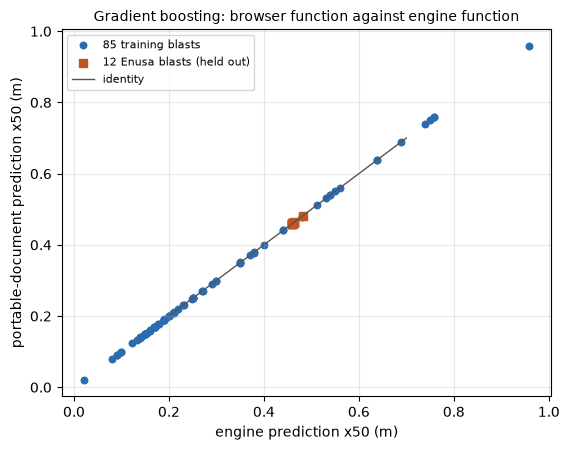

In [4]:
# Portable against engine prediction for all 97 blasts; orange: the campaign the model never saw
unseen = np.array([blast.site == held_out_site for blast in train])
fig, ax = plt.subplots(figsize=(5.8, 4.6))
ax.scatter(engine[~unseen], portable[~unseen], s=22, color="#2b6cb0", label="85 training blasts")
ax.scatter(engine[unseen], portable[unseen], s=30, marker="s", color="#c05621", label="12 Enusa blasts (held out)")
ax.plot([0.2, 0.7], [0.2, 0.7], color="#555", lw=1, label="identity")
ax.set_xlabel("engine prediction x50 (m)")
ax.set_ylabel("portable-document prediction x50 (m)")
ax.set_title("Gradient boosting: browser function against engine function", fontsize=10)
ax.legend(fontsize=8)
ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()

**What the figure shows.** All 97 points lie on the identity line: blue for the 85 training blasts and orange squares for the 12 Enusa blasts the model never saw, which collapse onto the same line. The output above says why: the largest absolute difference is 0.0e+00 m and all 97 predictions are bit-identical, because the reader walks the same trees and adds the same leaf values. **What it does not show:** accuracy. Parity says the browser computes the same function, not that the function is right. **What follows:** for boosting the document is the model, exactly.

### Step 3: the other learned predictors

The cell repeats the export for the network, the radial support vector regressor, the forest and the stacking ensemble. For each it keeps the absolute difference to the engine on every blast, and it sizes the document. It takes about ten seconds. Arithmetic differs by kind: the trees only compare and add stored numbers, whereas the network and the support vector regressor evaluate exponentials, where the order of floating-point operations can differ in the last digits.

In [5]:
# Export the other learned predictors and measure the same difference on every blast; about ten seconds
factories = bf.default_arms()
exported = {}
residuals = {}
rows = []
for name in ("published-neural-net", "svr-rbf", "random-forest", "xgboost", "stacking"):
    fitted = factories[name]().fit(fit_rows)
    exported[name] = bf.export_arm(fitted)
    gaps = [abs(fitted.predict_one(b).x50_m - bf.predict_portable(exported[name], b)[0]) for b in train]
    residuals[name] = np.array(gaps)
    rows.append((name, exported[name]["kind"], len(json.dumps(exported[name])), residuals[name].max()))
Table(["predictor", "document kind", "size (characters)", "largest difference (m)"],
      [(n, k, f"{s:,}", f"{g:.1e}") for n, k, s, g in rows])

| predictor | document kind | size (characters) | largest difference (m) |
|---|---|---|---|
| published-neural-net | network | 24,782 | 8.9e-16 |
| svr-rbf | svr | 9,114 | 2.8e-15 |
| random-forest | forest | 168,687 | 0.0e+00 |
| xgboost | xgboost | 40,032 | 0.0e+00 |
| stacking | stacking | 208,192 | 0.0e+00 |

The next cell draws two things about the five documents: their size on a logarithmic axis, which is what a browser would download, and the difference to the engine of each blast on another logarithmic axis, where 1e-17 stands for an exact zero. Look at which documents are big and which ones are not exact.

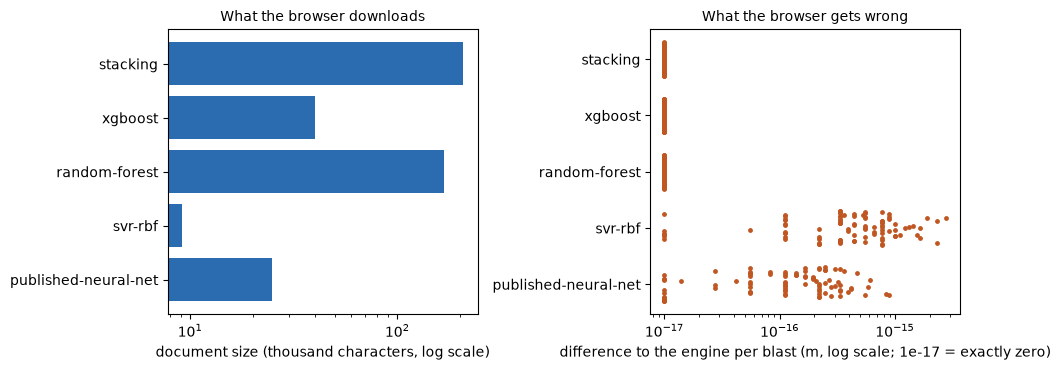

In [6]:
# Size of each portable document and the largest difference to the engine
fig, (ax, bx) = plt.subplots(1, 2, figsize=(9.8, 3.8))
names = [row[0] for row in rows]
ax.barh(names, [row[2] / 1000 for row in rows], color="#2b6cb0")
ax.set_xscale("log")
ax.set_xlabel("document size (thousand characters, log scale)")
ax.set_title("What the browser downloads", fontsize=10)
for k, name in enumerate(names):
    bx.scatter(np.maximum(residuals[name], 1e-17), np.full(len(train), k) + np.linspace(-0.3, 0.3, len(train)), s=6,
        color="#c05621")
bx.set_xscale("log")
bx.set_yticks(range(len(names)), names)
bx.set_xlabel("difference to the engine per blast (m, log scale; 1e-17 = exactly zero)")
bx.set_title("What the browser gets wrong", fontsize=10)
fig.tight_layout()
plt.show()

**What the figure shows.** The documents span more than a factor of twenty in size, from 9,114 characters for the support vector regressor to 208,192 for the stacking ensemble, which holds the forest and the boosted trees. The right panel shows the difference to the engine for each of the 97 blasts on a logarithmic axis where 1e-17 stands for exactly zero: the forest, boosting and stacking sit at zero, and the network and the support vector regressor differ by at most 8.9e-16 m and 2.8e-15 m, which is floating-point rounding. **What it does not show:** a ranking of the models, only that serving does not change them. **What follows:** a difference of a femtometre is not a difference, and the browser may use the document of any of the five.

### Step 4: move a design lever

The point of the document is that the prediction follows a design the reader changes. The cell takes Enusa blast `En1`, multiplies its burden ratio by 25 factors from 0.7 to 1.3 with the product's `apply_variant`, and predicts each design with the document and with a fresh fit of the engine, for gradient boosting and for the random forest.

In [7]:
# Move a design lever: burden multiplier from 0.7 to 1.3 on blast En1, portable against engine for two predictors
blast = next(b for b in train if b.blast_id == "En1")
multipliers = np.linspace(0.7, 1.3, 25)
designs = [apply_variant(blast, Variant("sweep", "", "", "B_over_D", float(m))) for m in multipliers]
sweep = {}
for name in ("xgboost", "random-forest"):
    fitted = factories[name]().fit(fit_rows)
    engine_curve = [fitted.predict_one(d).x50_m for d in designs]
    portable_curve = [bf.predict_portable(exported[name], d)[0] for d in designs]
    sweep[name] = (engine_curve, portable_curve)
    print(f"{name:<14} largest difference along the sweep:", f"{max(abs(a - b) for a, b in zip(*sweep[name])):.1e}",
        "m",
          f"| range of the response: {min(engine_curve):.4f} - {max(engine_curve):.4f} m")

xgboost        largest difference along the sweep: 0.0e+00 m | range of the response: 0.4598 - 0.4601 m
random-forest  largest difference along the sweep: 0.0e+00 m | range of the response: 0.4211 - 0.4338 m


The next cell draws the response to the burden multiplier of both predictors: the engine as a coloured line and the portable document as black markers on top of it. If the document did not follow the design, the markers would leave the line.

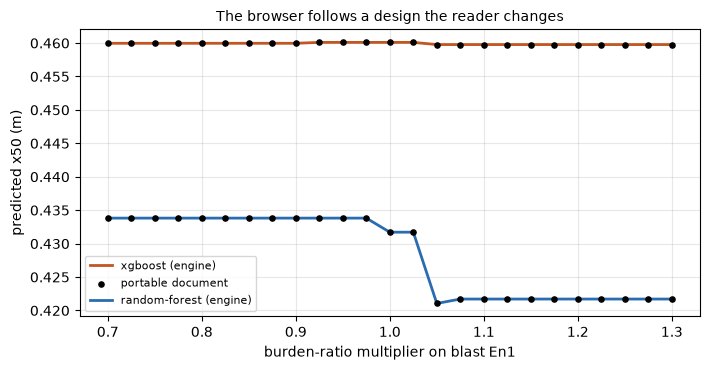

In [8]:
# The response to the burden for both predictors, engine as a line and portable document as markers
fig, ax = plt.subplots(figsize=(7.2, 3.8))
for (name, (engine_curve, portable_curve)), color in zip(sweep.items(), ("#c05621", "#2b6cb0")):
    ax.plot(multipliers, engine_curve, color=color, lw=2, label=f"{name} (engine)")
    ax.scatter(multipliers, portable_curve, color="black", s=14, zorder=3,
        label="portable document" if color == "#c05621" else None)
ax.set_xlabel("burden-ratio multiplier on blast En1")
ax.set_ylabel("predicted x50 (m)")
ax.set_title("The browser follows a design the reader changes", fontsize=10)
ax.legend(fontsize=8)
ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()

**What the figure shows.** The black markers (portable document) sit on both lines (engine) at all 25 multipliers, with a largest difference of 0.0e+00 m for both predictors. Both responses are steps, which is how tree models answer a smooth change: boosting stays between 0.4598 m and 0.4601 m, a step of a third of a millimetre, and the forest moves between 0.4338 m and 0.4211 m, falling as the burden widens. **What it does not show:** that the response has the right size or direction; the forest predicts a coarser design (a wider burden) as slightly finer, which the classical equation of notebook 01 of this topic would not. **What follows:** the browser reproduces the response, including its steps, so a design view built on the document shows the model as it is, flaws included.

### Step 5: the content address

Each models file ends with a content address: the SHA-256 of the file's canonical serialisation without its `digest` field, computed by the pipeline's `digest`. A reader who knows the address listed in the index can tell a stale or edited document. The cell tampers with a copy of the committed Enusa file: one leaf of the first tree of the forest moves by 1e-5, a hundredth of a millimetre. It recomputes the address and measures how much that leaf moves a forest prediction.

In [9]:
# Tamper with a copy of the committed Enusa document: one leaf moved by a hundredth of a millimetre
committed = json.loads((DERIVED / "models" / "Enusa.json").read_text(encoding="utf-8"))
payload = {key: value for key, value in committed.items() if key != "digest"}
tampered = copy.deepcopy(payload)
tampered["arms"]["random-forest"]["trees"][0]["t"][-1] += 1e-5
forest = copy.deepcopy(committed["arms"]["random-forest"])
forest["trees"][0]["t"][-1] += 1e-5
shift = max(abs(bf.predict_portable(forest, b)[0] - bf.predict_portable(committed["arms"]["random-forest"],
    b)[0]) for b in train)
Table(["", "content address (first 16 characters)", "largest change of a forest prediction (m)"],
      [("as committed", digest(payload)[:16], "0"),
          ("one leaf changed by 1e-5 m", digest(tampered)[:16], f"{shift:.1e}")])

|  | content address (first 16 characters) | largest change of a forest prediction (m) |
|---|---|---|
| as committed | e2a79809d8a7adc0 | 0 |
| one leaf changed by 1e-5 m | 2fe9f987034f7845 | 1.3e-07 |

**What the table shows.** The address changes completely (e2a79809d8a7adc0 becomes 2fe9f987034f7845) for a change that moves a forest prediction by at most 1.3e-07 m, a tenth of a micrometre. Nobody could see that change in a figure or in a table of predictions, and the address catches it. **What it does not show:** who made the change or why. The address detects a difference; it is not a signature. **What follows:** the product can serve a document from a static site and still know whether it is the committed one.

### Reproduction check: the fresh export equals the committed document

The Enusa scope of the product was exported by the offline bake from this same fit. The cell compares each fresh export of step 3 with the committed arm, and recomputes the content address of the committed file against the stored one and the one the index lists. The stacking document is stored differently in the committed file, which the cell also prints.

In [10]:
# The one reproduction check: the fresh exports equal the committed arms and the address equals the stored one and the
# index's
index = json.loads((DERIVED / "manifests" / "index.json").read_text(encoding="utf-8"))
listed = next(entry["digest"] for entry in index["models"] if entry["scope"] == held_out_site)
same = [name for name, doc in exported.items() if doc == committed["arms"][name]]
print("fresh export identical to the committed document, predictors:", same)
print("stacking in the committed file keeps its parts by reference:",
      committed["arms"]["stacking"]["forest"], committed["arms"]["stacking"]["boosting"])
print("address recomputed equals the stored one:", digest(payload) == committed["digest"], "| and the index's:",
    digest(payload) == listed)

fresh export identical to the committed document, predictors: ['published-neural-net', 'svr-rbf', 'random-forest', 'xgboost']
stacking in the committed file keeps its parts by reference: {'ref': 'random-forest'} {'ref': 'xgboost'}
address recomputed equals the stored one: True | and the index's: True


## Results

**Answer:** yes. A learned model can be served from a portable document with exactly the engine's predictions, and the five predictors tested differ from the engine by at most 2.8e-15 m, three of them by exactly zero. The gradient boosting document is 40,032 characters, 100 trees, and reproduces the engine on all 97 blasts, the 12 Enusa blasts it was not trained on included, bit for bit. The network and the support vector regressor differ by 8.9e-16 m and 2.8e-15 m, floating-point rounding. Along a sweep of the burden the document and the engine give the same steps, with a largest difference of 0.0e+00 m for both predictors tested. A change of one leaf by 1e-5 m changes the content address, while moving a forest prediction by less than 1.3e-07 m, and the fresh export equals the committed one for the network, the support vector regressor, the forest and boosting, with the address matching the stored one and the index's.

Beyond the state of the art, which offers a score and a recipe, this is a function a browser can call with a way to know it is the right one, which is the claim BS-5.

**What this does not show.** Parity of two readers says the browser computes the same function, not that the function is accurate: held out by Enusa, the learned predictors score near or below zero, as notebook 01 of topic 05 measured. The stacking document is stored by reference in the committed file, so it is compared by predictions in step 3 and not byte for byte. And the content address detects change; it does not say who changed the document.

## Summary

- A fitted learned predictor is exported by `export_arm` to a JSON document of arrays; gradient boosting is 100 trees in 40,032 characters.
- The reference reader reproduces the engine on all 97 blasts, exactly for the trees and to 2.8e-15 m for the network and the support vector regressor, and it follows a design lever step for step (claim BS-5).
- A content address moves for a change of 1e-5 m in one leaf, and the fresh export equals the committed document.
- This closes the set: the data, the classical equation, the curves, the protocol, the learned predictors and the live response.

## References

- Kulatilake, Hudaverdi and Wu 2012, https://doi.org/10.1007/s10706-012-9496-3 (the back-propagation network and its hold-out)
- Amoako, Jha and Zhong 2022, https://doi.org/10.3390/mining2020013 (support vector regression, rbf kernel; the classical equation)
- Sui, Zhou, Zhao, Yang and Zou 2025, https://doi.org/10.3390/app15031254 (support vector polynomial, forest, boosting, stacking)
- Hudaverdi, Kulatilake and Kuzu 2010, https://doi.org/10.1002/nag.957 (the corpus and the published regression)
- `blastfrag` 0.4.0, the engine, on PyPI: https://pypi.org/project/blastfrag/